JS04 Tugas 2 - DBSCAN pada make_moons + eksperimen parameter.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("tugas_dbscan.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js04-klasterisasi\tugas


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn import metrics
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

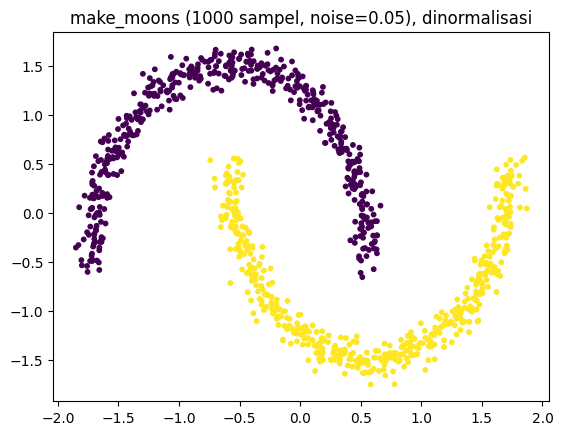

In [3]:
# 1. Dataset make_moons + normalisasi
X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)
X = StandardScaler().fit_transform(X)

plt.scatter(X[:, 0], X[:, 1], s=10, c=y, cmap="viridis")
plt.title("make_moons (1000 sampel, noise=0.05), dinormalisasi")
plt.savefig(OUT / "01_moons.png", dpi=120, bbox_inches="tight")

In [4]:
# 2. DBSCAN eps=0.2, min_samples=5
db = DBSCAN(eps=0.2, min_samples=5).fit(X)
labels = db.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
print(f"eps=0.2, min_samples=5 -> klaster: {n_clusters}, noise: {n_noise}")

eps=0.2, min_samples=5 -> klaster: 2, noise: 0


In [5]:
# 3. Evaluasi
print(f"Homogeneity: {metrics.homogeneity_score(y, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(y, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(y, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(y, labels):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(y, labels):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index: 1.000
Adjusted Mutual Information: 1.000
Silhouette Coefficient: 0.391


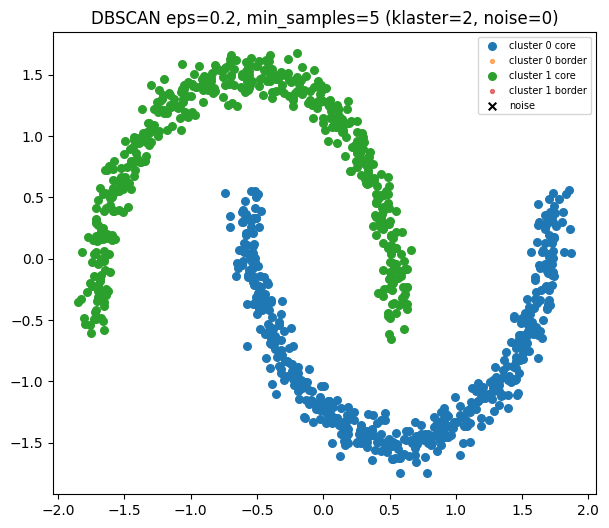

In [6]:
# 4. Visualisasi core / non-core / noise
core_mask = np.zeros_like(labels, dtype=bool)
core_mask[db.core_sample_indices_] = True
noise = labels == -1

plt.figure(figsize=(7, 6))
for k in sorted(set(labels) - {-1}):
    m = labels == k
    plt.scatter(*X[m & core_mask].T, s=30, label=f"cluster {k} core")
    plt.scatter(*X[m & ~core_mask].T, s=8, alpha=0.6, label=f"cluster {k} border")
plt.scatter(*X[noise].T, s=30, c="black", marker="x", label="noise")
plt.title(f"DBSCAN eps=0.2, min_samples=5 (klaster={n_clusters}, noise={n_noise})")
plt.legend(fontsize=7, loc="upper right")
plt.savefig(OUT / "02_dbscan_hasil.png", dpi=120, bbox_inches="tight")

In [7]:
# 5. Eksperimen eps x min_samples
print(f"\n{'eps':>5} {'min_samples':>12} {'klaster':>8} {'noise':>6} {'ARI':>6} {'Silhouette':>11}")
rows = []
for eps in (0.05, 0.1, 0.3, 0.5):
    for min_samples in (3, 10, 20):
        L = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
        n_c = len(set(L)) - (1 if -1 in L else 0)
        n_n = list(L).count(-1)
        ari = metrics.adjusted_rand_score(y, L)
        s = metrics.silhouette_score(X, L) if n_c > 1 else float("nan")
        print(f"{eps:>5} {min_samples:>12} {n_c:>8} {n_n:>6} {ari:>6.3f} {s:>11.3f}")
        rows.append(dict(eps=eps, min_samples=min_samples, clusters=n_c, noise=n_n, ARI=ari, silhouette=s))


  eps  min_samples  klaster  noise    ARI  Silhouette
 0.05            3       69    186  0.030       0.113
 0.05           10        3    970  0.002      -0.294
 0.05           20        0   1000  0.000         nan
  0.1            3        2     14  0.972       0.252
  0.1           10        7     57  0.523       0.162
  0.1           20        6    850  0.017      -0.360
  0.3            3        2      0  1.000       0.391
  0.3           10        2      0  1.000       0.391
  0.3           20        2      0  1.000       0.391


  0.5            3        2      0  1.000       0.391
  0.5           10        2      0  1.000       0.391
  0.5           20        2      0  1.000       0.391


In [8]:
# simpan tabel eksperimen
import csv
with open(OUT / "eksperimen.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0]))
    w.writeheader()
    w.writerows(rows)
print("\nTabel eksperimen:", OUT / "eksperimen.csv")


Tabel eksperimen: C:\code\pemmes26\js04-klasterisasi\tugas\output\eksperimen.csv
